# PyTorch Tutorial

**Author:** Nassim Razaaly ([nassim.razaaly@ensma.fr](mailto:nassim.razaaly@ensma.fr))  
**First version:** October 12, 2026  
**Last updated:** October 15, 2026


1. Tensors · 2. Autograd · 3. `torch.nn` · 4. Training: 1D regression with an MLP · 5. Going further

Adapted from the CS224N PyTorch notebook and the official [60 Minute Blitz](https://pytorch.org/tutorials/beginner/deep_learning_60min_blitz.html).

> **Colab:** *File → Save a copy in Drive* first. Runs on CPU in under a minute, no GPU needed.

**Dependencies:** `torch>=2.0`, `numpy`, `matplotlib`, `tqdm` (preinstalled on Colab), and `torchinfo` (installed by the first cell).

In [ ]:
!pip install -q torchinfo                  # not preinstalled on Colab
# Outside Colab, also:
# !pip install "torch>=2.0" numpy matplotlib tqdm

import copy                             # to save the best weights
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from tqdm.auto import tqdm              # progress bars
from IPython.display import display     # live plots
from torchinfo import summary           # model summary table

torch.manual_seed(0)
print("torch", torch.__version__, "| numpy", np.__version__)

## 1. Tensors

A tensor is a multi-dimensional array (like a NumPy array) that can run on GPU and track gradients. Each tensor has a **shape** and a **dtype**, mostly `torch.float32` or `torch.int64`.

In [ ]:
a = torch.tensor([[0, 1], [2, 3], [4, 5]])
b = torch.tensor([[0, 1], [2, 3], [4, 5]], dtype=torch.float32)
print(a, a.dtype, a.shape)
print(b, b.dtype)

print(torch.zeros(2, 3))
print(torch.ones(2, 3))
print(torch.arange(1, 10))
print(torch.linspace(0, 1, 5))   # 5 evenly spaced values in [0, 1]

Element-wise arithmetic, matrix product `@`, reshaping, and NumPy conversion:

In [ ]:
r = torch.arange(1, 7)
print(r * 2 + 1)

A = torch.ones(3, 2)
B = torch.ones(2, 4)
print((A @ B).shape)          # (3, 2) @ (2, 4) -> (3, 4)

print(r.view(2, 3))           # reshape: values are read row by row
print(r.view(-1, 1).shape)    # -1 = "infer this size": (6,) -> (6, 1), a column

arr = r.numpy()               # tensor -> numpy
print(torch.tensor(arr))      # numpy -> tensor

**Reductions** (`sum`, `mean`, `std`…) take a `dim` argument: it is the dimension that **disappears**.
`dim=0` → one value per column, `dim=1` → one value per row.

In [ ]:
data = torch.arange(1, 13, dtype=torch.float32).view(3, 4)
print(data)
print(data.sum(dim=0))   # per column, shape (4,)
print(data.sum(dim=1))   # per row,    shape (3,)
print(data.sum())        # everything

**Indexing** works like NumPy. `.item()` turns a one-value tensor into a Python number.

In [ ]:
m = torch.arange(1, 16).view(5, 3)
print(m)
print(m[0])           # first row
print(m[:, 0])        # first column
print(m[1:3, 0:2])    # block
print(m[[0, 2, 4]])   # rows 0, 2, 4
print(m[0, 2].item()) # Python int

# Pitfall: these are different!
print(m[0:3, 2])      # column 2 of rows 0-2  -> [3, 6, 9]
print(m[0:3][2])      # row 2 of the slice    -> [7, 8, 9]

### Exercise

Create $\begin{bmatrix} 1 & 2.2 & 9.6 \\ 4 & -7.2 & 6.3 \end{bmatrix}$, then get its first row, its first column, and the mean of each row and of each column. What are the shapes?

In [ ]:
# Your code here

In [ ]:
# Solution
t = torch.tensor([[1, 2.2, 9.6], [4, -7.2, 6.3]])
print(t[0], t[:, 0])
print(t.mean(dim=1), t.mean(dim=1).shape)   # row means, shape (2,)
print(t.mean(dim=0), t.mean(dim=0).shape)   # column means, shape (3,)

## 2. Autograd

PyTorch can compute derivatives automatically. If a tensor is created with `requires_grad=True`, PyTorch records every operation applied to it (the *computation graph*). Calling `.backward()` on the result then computes the gradients, which are stored in the `.grad` attribute.

### A first derivative

In [ ]:
x = torch.tensor(2.0, requires_grad=True)
print(x)
print("requires_grad:", x.requires_grad)
print("grad:", x.grad)   # None: nothing computed yet

Let's compute $y = 3x^2$. The result remembers how it was obtained (`grad_fn`):

In [ ]:
y = 3 * x ** 2
print(y)
print(y.grad_fn)

`y.backward()` computes $\frac{dy}{dx} = 6x$, i.e. $12$ at $x = 2$:

In [ ]:
y.backward()
print(x.grad)

### Gradients accumulate

If we run backprop again, the new gradient is **added** to the old one:

In [ ]:
y = 3 * x ** 2
y.backward()
print(x.grad)   # 12 + 12 = 24, not 12!

We must reset it by hand. In a training loop, this is what `optimizer.zero_grad()` does at every step.

In [ ]:
x.grad.zero_()
print(x.grad)

### Several variables

Autograd works with any number of inputs. Example: a tiny linear model $\hat y = w x + b$ with a squared error loss $L = (\hat y - y)^2$.

By hand: $\frac{\partial L}{\partial w} = 2(\hat y - y)\,x$ and $\frac{\partial L}{\partial b} = 2(\hat y - y)$.

In [ ]:
w = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(0.5, requires_grad=True)
x_in, y_true = torch.tensor(2.0), torch.tensor(4.0)

y_hat = w * x_in + b            # 2.5
loss = (y_hat - y_true) ** 2    # 2.25
loss.backward()

print("dL/dw autograd:", w.grad.item(), "| by hand:", (2 * (y_hat - y_true) * x_in).item())
print("dL/db autograd:", b.grad.item(), "| by hand:", (2 * (y_hat - y_true)).item())

### Derivative of a whole curve

`x` can also be a vector of points. `.backward()` needs a **scalar**, so we call it on `y.sum()`: since each `y[i]` only depends on `x[i]`, `x.grad[i]` is exactly $f'(x_i)$.

Check with $f(x) = x \sin(x)$, whose derivative is $f'(x) = \sin(x) + x\cos(x)$:

In [ ]:
x = torch.linspace(-6, 6, 200, requires_grad=True)
y = x * torch.sin(x)
y.sum().backward()

x_np = x.detach().numpy()   # .detach(): a tensor that requires grad must be detached before .numpy()
plt.figure(figsize=(8, 4))
plt.plot(x_np, y.detach().numpy(), label="f(x) = x sin(x)")
plt.plot(x_np, x.grad.numpy(), label="f'(x) with autograd", lw=3)
plt.plot(x_np, np.sin(x_np) + x_np * np.cos(x_np), "k--", label="f'(x) by hand")
plt.legend(); plt.title("Autograd vs analytic derivative"); plt.show()

### Turning gradients off

When we only want to *use* a model (evaluation, plotting), gradients are useless. `torch.no_grad()` disables them, which is faster and uses less memory.

In [ ]:
x = torch.tensor(2.0, requires_grad=True)
with torch.no_grad():
    z = 3 * x ** 2
print(z, "| requires_grad:", z.requires_grad)

### Gradient descent by hand

We minimize $L(x) = (x - x^*)^2$, whose minimum is at $x = x^*$ (here $x^* = 3$). Starting from $x_0 = 0$, each iteration computes the gradient and takes a small step in the opposite direction:

$$x \leftarrow x - \text{lr} \cdot \frac{dL}{dx}$$

In [ ]:
x_star = 3.0                                  # the minimum x*
x = torch.tensor(0.0, requires_grad=True)     # starting point x_0
lr = 0.1
n_iter = 30
x_hist, loss_hist = [], []

for it in range(n_iter):
    loss = (x - x_star) ** 2
    loss.backward()                           # compute dL/dx
    x_hist.append(x.item())
    loss_hist.append(loss.item())
    if it % 5 == 0:
        print(f"it {it:2d} | x = {x.item():.4f} | L = {loss.item():.6f} | dL/dx = {x.grad.item():.4f}")
    with torch.no_grad():
        x -= lr * x.grad                      # update (must not be recorded by autograd)
    x.grad.zero_()                            # reset for the next iteration

print(f"final x = {x.item():.4f}   (x* = {x_star})")

Since $\frac{dL}{dx} = 2(x - x^*)$, one iteration gives $x_{k+1} - x^* = (1 - 2\,\text{lr})(x_k - x^*) = 0.8\,(x_k - x^*)$:

* $x$ converges geometrically to $x^*$;
* $L = (x - x^*)^2$ is multiplied by $0.8^2 = 0.64$ at each iteration: a straight line in log scale.

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

ax[0].plot(x_hist, "o-")
ax[0].axhline(x_star, color="k", ls="--", label="$x^*$")
ax[0].set(xlabel="iteration", ylabel="x", title="x vs iteration")
ax[0].legend()

ax[1].plot(loss_hist, "o-", color="tab:red")
ax[1].set(xlabel="iteration", ylabel="L(x)", yscale="log", title="Loss vs iteration (log scale)")

plt.tight_layout(); plt.show()

This is exactly what a PyTorch **optimizer** does for us, for all the parameters of a network at once (section 4).

## 3. `torch.nn`

Writing every weight by hand quickly becomes painful. `torch.nn` provides ready-made **layers** that create and store their parameters.

### Linear layer

`nn.Linear(n_in, n_out)` computes $x W^T + b$. Its weights $W$ (shape `(n_out, n_in)`) and bias $b$ (shape `(n_out,)`) are initialized randomly.

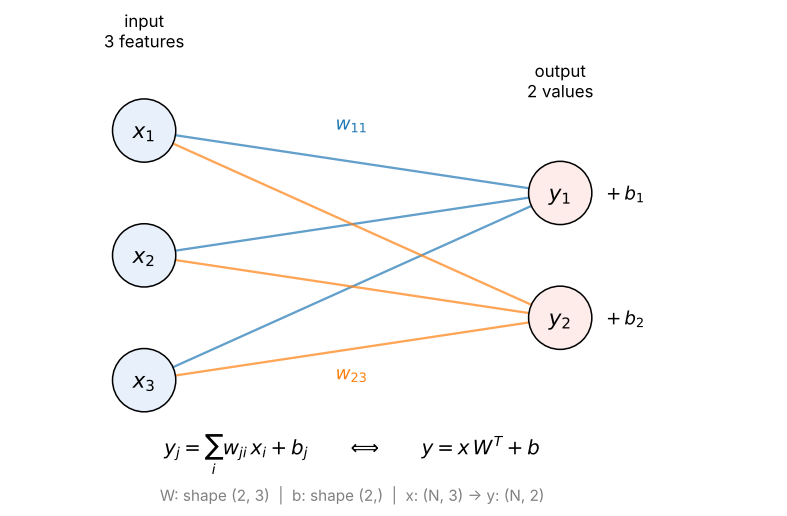

In [ ]:
layer = nn.Linear(3, 2)
print(layer)
print("W =", layer.weight)
print("b =", layer.bias)

The input is a **batch**: one row per sample, one column per feature. Here, 4 samples with 3 features each:

In [ ]:
x = torch.randn(4, 3)
out = layer(x)
print("input :", x.shape)
print("output:", out.shape)   # (4, 2): 4 samples, 2 outputs each

Let's check that it really computes $x W^T + b$:

In [ ]:
manual = x @ layer.weight.T + layer.bias
print(torch.allclose(out, manual))

The parameters have `requires_grad=True`: they will be trained.

In [ ]:
for name, p in layer.named_parameters():
    print(name, tuple(p.shape), "requires_grad =", p.requires_grad)

### Activation functions

Stacking linear layers alone gives... a linear function. **Activation functions** add non-linearity. They are applied element-wise: the output has the same shape as the input.

In [ ]:
# @title Display function `plot_activation` (run this cell; no need to read the code)
z = torch.linspace(-4, 4, 200)

def plot_activation(act, name, equation, comment):
    fig, (ax_plot, ax_text) = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1, 1.15]})

    # left: the curve
    ax_plot.plot(z, act(z), lw=2.5)
    ax_plot.axhline(0, color="gray", lw=0.6); ax_plot.axvline(0, color="gray", lw=0.6)
    ax_plot.set(xlabel="z", title=name)
    ax_plot.grid(alpha=0.3)

    # right: equation and comment
    ax_text.axis("off")
    ax_text.text(0.02, 0.80, equation, fontsize=20, va="center")
    ax_text.text(0.02, 0.45, comment, fontsize=11.5, va="top", linespacing=1.6)

    plt.tight_layout(); plt.show()

In [ ]:
plot_activation(
    nn.ReLU(), "ReLU",
    r"$\mathrm{ReLU}(z) = \max(0,\, z)$",
    "• Zero for z < 0, identity for z > 0.\n"
    "• Cheap to compute: the default choice in deep networks.\n"
    "• Derivative 0 or 1: the fit is piecewise linear.",
)

In [ ]:
plot_activation(
    nn.LeakyReLU(negative_slope=0.1), "Leaky ReLU",
    r"$\mathrm{LeakyReLU}(z) = \max(\alpha z,\, z)$",
    "• Like ReLU, with a small slope α for z < 0\n"
    "   (default α = 0.01; here α = 0.1 to make it visible).\n"
    "• Gradient α instead of 0 for z < 0: neurons never 'die'.",
)

In [ ]:
plot_activation(
    nn.GELU(), "GELU",
    r"$\mathrm{GELU}(z) = z\,\Phi(z)$",
    "• Φ: cumulative distribution function of N(0, 1).\n"
    "• Smooth version of ReLU, slightly negative for z < 0.\n"
    "• Default in transformers (BERT, GPT, ...).",
)

In [ ]:
plot_activation(
    nn.SiLU(), "SiLU (Swish)",
    r"$\mathrm{SiLU}(z) = z\,\sigma(z) = \dfrac{z}{1 + e^{-z}}$",
    "• Also called Swish. σ: the sigmoid (below).\n"
    "• Smooth, very close to GELU.\n"
    "• Used in recent CNNs and LLMs (EfficientNet, LLaMA's SwiGLU).",
)

In [ ]:
plot_activation(
    nn.Mish(), "Mish",
    r"$\mathrm{Mish}(z) = z\,\tanh\left(\ln(1 + e^{z})\right)$",
    "• Smooth, very close to SiLU.\n"
    "• Used e.g. in the YOLOv4 object detector.\n"
    "• Slightly more expensive to compute.",
)

In [ ]:
plot_activation(
    nn.Tanh(), "Tanh",
    r"$\tanh(z) = \dfrac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$",
    "• Smooth, output in (-1, 1), centered on 0.\n"
    "• Smooth fits: a good choice for small regression networks.\n"
    "• Saturates for large |z| (derivative close to 0).",
)

In [ ]:
plot_activation(
    nn.Sigmoid(), "Sigmoid",
    r"$\sigma(z) = \dfrac{1}{1 + e^{-z}}$",
    "• Smooth, output in (0, 1): can be read as a probability.\n"
    "• Typical output of a binary classifier.\n"
    "• Saturates like tanh; rarely used in hidden layers.",
)

### Chaining layers: `nn.Sequential`

`nn.Sequential` passes the output of each layer to the next one. Example: 1 input → a hidden layer of 3 neurons with `tanh` → 1 output.

$$h = \tanh(x\,W_1^T + b_1), \qquad \hat y = h\,W_2^T + b_2$$

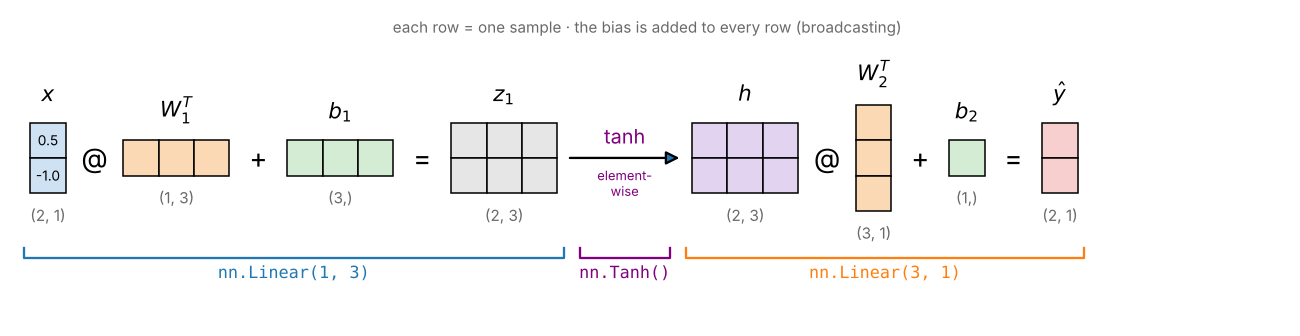

In [ ]:
torch.manual_seed(0)
block = nn.Sequential(
    nn.Linear(1, 3),   # W1: (3, 1), b1: (3,)
    nn.Tanh(),
    nn.Linear(3, 1),   # W2: (1, 3), b2: (1,)
)
print(block)

Input: 2 samples with 1 feature each, shape `(2, 1)`. Expected output: one value per sample, shape `(2, 1)`.

In [ ]:
x = torch.tensor([[0.5], [-1.0]])
y_hat = block(x)
print("input :", x.shape)
print("output:", y_hat.shape)
print(y_hat)

Check: compute the two equations by hand with the block's own parameters (layers are accessed by index).

In [ ]:
lin1, lin2 = block[0], block[2]
h = torch.tanh(x @ lin1.weight.T + lin1.bias)    # hidden layer, shape (2, 3)
y_manual = h @ lin2.weight.T + lin2.bias         # output,       shape (2, 1)

print("h:", h.shape, "| y_manual:", y_manual.shape)
print("same result:", torch.allclose(y_hat, y_manual))

### Custom model: subclass `nn.Module`

The standard way to define a model:


1. in `__init__`, call `super().__init__()` and create the layers;
2. in `forward`, describe the computation.

Calling `model(x)` runs `forward(x)`, and the parameters of all layers are registered automatically.

Our **multilayer perceptron (MLP)** for regression: 1 input → two hidden layers of $H$ neurons with `tanh` → 1 output. No activation on the output, since we predict any real value:

$$h_1 = \tanh(x\,W_1^T + b_1), \qquad h_2 = \tanh(h_1 W_2^T + b_2), \qquad \hat y = h_2 W_3^T + b_3$$

with $W_1$: $(H, 1)$, $W_2$: $(H, H)$, $W_3$: $(1, H)$. Number of parameters: $(H + H) + (H^2 + H) + (H + 1) = H^2 + 4H + 1$.

The method `n_params` counts them.

In [ ]:
class MLP(nn.Module):
    def __init__(self, n_in=1, n_hidden=64, n_out=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, n_hidden), nn.Tanh(),
            nn.Linear(n_hidden, n_hidden), nn.Tanh(),
            nn.Linear(n_hidden, n_out),
        )

    def forward(self, x):
        return self.net(x)

    def n_params(self):
        return sum(p.numel() for p in self.parameters())

A simple example: create a small model ($H = 4$), run it on 3 inputs, check the shapes and the number of parameters ($4^2 + 4 \times 4 + 1 = 33$).

In [ ]:
model = MLP(n_hidden=4)
x = torch.tensor([[0.0], [1.0], [2.0]])      # 3 samples, shape (3, 1)
y_hat = model(x)

print("input :", x.shape)
print("output:", y_hat.shape)                # (3, 1): one prediction per sample
print("number of parameters:", model.n_params())

The default model ($H = 64$) used later. `print` lists the layers:

In [ ]:
model = MLP()
print(model)

`torch.nn` has no built-in drawing of a network. The `torchinfo` package gives a clearer summary: for a given input size, the output shape and the number of parameters of each layer.

In [ ]:
summary(model, input_size=(200, 1))   # (N samples, 1 feature)

Number of parameters: $(1 \times 64 + 64) + (64 \times 64 + 64) + (64 \times 1 + 1) = 4353$.

In [ ]:
for name, p in model.named_parameters():
    print(f"{name:15s} {str(tuple(p.shape)):10s} {p.numel()}")
print("total:", model.n_params())

### Example: input → model → output

Inputs are given as a column of shape `(N, 1)`: one row per sample. Here 5 inputs, so 5 predictions:

In [ ]:
x = torch.linspace(-3, 3, 5).view(-1, 1)   # shape (5, 1)
y_hat = model(x)

print("input :", x.shape)
print("output:", y_hat.shape)
print(y_hat)

An untrained model is just a random smooth function:

In [ ]:
x_grid = torch.linspace(-3, 3, 500).view(-1, 1)
with torch.no_grad():
    plt.figure(figsize=(8, 3))
    for seed in range(3):
        torch.manual_seed(seed)
        plt.plot(x_grid, MLP()(x_grid), label=f"random init {seed}")
plt.legend(); plt.title("Untrained MLPs"); plt.show()

### Loss function: mean squared error (MSE)

For $N$ predictions $\hat y_i$ and targets $y_i$:

$$\mathrm{MSE} = \frac{1}{N}\sum_{i=1}^{N} (\hat y_i - y_i)^2$$

It is $\geq 0$, equal to 0 only if every prediction is exact, and it penalizes large errors more (squared). Its unit is the square of the unit of $y$.

In PyTorch: `loss_fn = nn.MSELoss()`, then `loss_fn(prediction, target)`. Both tensors must have the **same shape**, e.g. `(N, 1)`.

By hand, step by step, on 3 samples:

In [ ]:
y_hat  = torch.tensor([[1.0], [2.0], [3.0]])   # predictions, shape (3, 1)
y_true = torch.tensor([[1.5], [2.0], [2.0]])   # targets,     shape (3, 1)

errors = y_hat - y_true          # [-0.5, 0, 1]
squared = errors ** 2            # [0.25, 0, 1]
mse_manual = squared.mean()      # (0.25 + 0 + 1) / 3

print("errors :", errors.flatten())
print("squared:", squared.flatten())
print("MSE by hand:", mse_manual.item())

The same with `nn.MSELoss`, and as a one-line function:

In [ ]:
loss_fn = nn.MSELoss()
print("nn.MSELoss :", loss_fn(y_hat, y_true).item())

def mse(y_hat, y_true):
    return ((y_hat - y_true) ** 2).mean()

print("mse function:", mse(y_hat, y_true).item())

## 4. Training: 1D regression with an MLP

Goal: learn a function from noisy samples of it. The procedure:


1. **Data:** generate noisy samples $(x_i, y_i)$ of a known function $f$.
2. **Split** them into training, validation and test sets.
3. **Model, loss, optimizer:** an MLP, the MSE, and Adam.
4. **Training:** update the weights to minimize the training loss, while monitoring the validation loss.
5. **Evaluation:** measure the final error on the test set.

We use a very small model; larger models are explored in section 5.

### Data

The true function is:

$$f(x) = \sin(3x) + 0.3\,x^2 - 1.5\, e^{-10(x-1)^2}$$

In practice $f$ is unknown: we only have measurements. Here we choose it, so we can check what the model learns.

In [ ]:
def f(x):
    return torch.sin(3 * x) + 0.3 * x**2 - 1.5 * torch.exp(-10 * (x - 1) ** 2)

In [ ]:
# Same colors and styles in all the plots of this section
C_TRAIN, C_VAL, C_TEST = "tab:blue", "tab:orange", "tab:green"   # data sets
C_PRED = "tab:red"                                                 # model prediction
TRUE = dict(color="k", ls="--", lw=1.5, label="true f(x)")         # true function
NOISE = dict(color="gray", ls=":", lw=1.5, label="noise level")    # noise variance

We draw $N = 200$ inputs $x_i$ uniformly in $[-3, 3]$ and add Gaussian noise of standard deviation $\sigma = 0.2$:

$$y_i = f(x_i) + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal{N}(0, \sigma^2)$$

Inputs and targets are stored as columns of shape `(200, 1)`, the format expected by `nn.Linear`.

In [ ]:
torch.manual_seed(0)
N, noise = 200, 0.2
x = torch.rand(N, 1) * 6 - 3                 # uniform in [-3, 3]
y = f(x) + noise * torch.randn(N, 1)         # noisy targets

print("x:", x.shape, "| y:", y.shape)
print(torch.cat([x, y], dim=1)[:5])          # first 5 (x, y) pairs

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(x_grid, f(x_grid), **TRUE)
plt.scatter(x, y, s=12, color="gray", alpha=0.7, label="noisy data")
plt.legend(); plt.title("Data"); plt.show()

We split the data at random into three sets:

* **training (60 %)**: used to compute the loss and update the weights;
* **validation (20 %)**: never used to update the weights. It serves to *monitor* training (comparing training and validation losses reveals under- or overfitting) and to choose hyperparameters (network size, number of epochs: see section 5);
* **test (20 %)**: used only once, at the end, to estimate the error on unseen data.

In [ ]:
perm = torch.randperm(N)
n_train, n_val = int(0.6 * N), int(0.2 * N)
train_idx = perm[:n_train]
val_idx = perm[n_train:n_train + n_val]
test_idx = perm[n_train + n_val:]

x_train, y_train = x[train_idx], y[train_idx]
x_val, y_val = x[val_idx], y[val_idx]
x_test, y_test = x[test_idx], y[test_idx]
print("train:", x_train.shape, "| validation:", x_val.shape, "| test:", x_test.shape)

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(x_grid, f(x_grid), **TRUE)
plt.scatter(x_train, y_train, s=15, color=C_TRAIN, label="train")
plt.scatter(x_val, y_val, s=15, color=C_VAL, label="validation")
plt.scatter(x_test, y_test, s=15, color=C_TEST, label="test")
plt.legend(); plt.title("Data split"); plt.show()

### Small model: model, loss, optimizer

We start with a very small MLP: $H = 4$, only 33 parameters.

The **optimizer** updates the parameters from their gradients, like our hand-written gradient descent, but for all parameters at once. We use **Adam**, a popular variant of gradient descent, with learning rate `1e-2`.

In [ ]:
torch.manual_seed(0)
model_small = MLP(n_hidden=4)
print("parameters:", model_small.n_params())

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model_small.parameters(), lr=1e-2)

Before training: the loss is high and the prediction is far from the data.

In [ ]:
with torch.no_grad():
    print("initial train MSE:", loss_fn(model_small(x_train), y_train).item())
    print("initial val MSE  :", loss_fn(model_small(x_val), y_val).item())

    plt.figure(figsize=(8, 4))
    plt.scatter(x_train, y_train, s=10, color=C_TRAIN, alpha=0.5, label="train")
    plt.plot(x_grid, f(x_grid), **TRUE)
    plt.plot(x_grid, model_small(x_grid), color=C_PRED, lw=2, label="MLP (untrained)")
    plt.legend(); plt.title("Before training"); plt.show()

### One training step, in detail

A training step has 4 parts: **zero the gradients → forward → backward → update**.

In [ ]:
optimizer.zero_grad()                          # 1. reset gradients
y_pred = model_small(x_train)                  # 2. forward pass
loss = loss_fn(y_pred, y_train)
print("loss before step:", loss.item())

loss.backward()                                # 3. backward pass: fills p.grad
print("gradient of the first layer's weights:", model_small.net[0].weight.grad.shape)

optimizer.step()                               # 4. update the parameters

with torch.no_grad():
    print("loss after step :", loss_fn(model_small(x_train), y_train).item())

### Full training loop

We repeat this step for 2000 **epochs** (one epoch = one pass over the training set; here the whole set is used at each step, which is fine for 120 points).

The weights are updated with the **training loss only**. At each epoch we also compute the validation loss (with `torch.no_grad()`, no update) to plot both curves, and we save the predicted curve at a few epochs to watch the fit evolve.

We restart from a fresh model so the results don't depend on the step above.

In [ ]:
torch.manual_seed(0)
model_small = MLP(n_hidden=4)
optimizer = torch.optim.Adam(model_small.parameters(), lr=1e-2)

n_epochs = 2000
snapshot_epochs = [0, 50, 200, 500, n_epochs - 1]
train_losses, val_losses, snapshots = [], [], {}

for epoch in range(n_epochs):
    # --- training step ---
    model_small.train()
    optimizer.zero_grad()
    loss = loss_fn(model_small(x_train), y_train)
    loss.backward()
    optimizer.step()

    # --- monitoring (no gradients, no update) ---
    model_small.eval()
    with torch.no_grad():
        val_loss = loss_fn(model_small(x_val), y_val)
        if epoch in snapshot_epochs:
            snapshots[epoch] = model_small(x_grid)

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())
    if epoch % 250 == 0 or epoch == n_epochs - 1:
        print(f"epoch {epoch:4d} | train MSE {loss.item():.4f} | val MSE {val_loss.item():.4f}")

### Loss curves

The dotted line is the noise variance $\sigma^2 = 0.2^2 = 0.04$. Why it matters: for a new point, $y = f(x) + \varepsilon$ with $\varepsilon$ independent of $x$, of mean 0 and variance $\sigma^2$. For any model $g$, the expected error is

$$\mathbb{E}\left[(g(x) - y)^2\right] = \mathbb{E}\left[(g(x) - f(x))^2\right] + \sigma^2 \;\geq\; \sigma^2$$

with equality only if $g = f$: the noise cannot be predicted. Consequences:

* **validation / test MSE**: about $\sigma^2$ at best (a finite set can give slightly less, by chance);
* **training MSE**: *can* go below $\sigma^2$, because the model has seen these very points and can fit their noise: a sign of **overfitting**;
* a training MSE clearly **above** $\sigma^2$: the model cannot even follow $f$ on the training points: it **underfits**.

The log scale makes small values readable.

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(train_losses, color=C_TRAIN, label="train")
plt.plot(val_losses, color=C_VAL, label="validation")
plt.axhline(noise**2, **NOISE)
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE")
plt.legend(); plt.title("Loss curves (small model)"); plt.show()

### How the fit evolves during training

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(x_grid, f(x_grid), **TRUE)
for k, (epoch, pred) in enumerate(snapshots.items()):
    t = (k + 1) / len(snapshots)                  # from early (small t) to late (t = 1)
    final = epoch == n_epochs - 1
    plt.plot(x_grid, pred, color=plt.cm.Reds(0.25 + 0.75 * t), lw=0.8 + 1.7 * t,
             ls="-" if final else "-.", label=f"epoch {epoch}")
plt.legend(fontsize=8); plt.title("Fit during training (small model): light = early, dark = late"); plt.show()

### Final fit

Compare the red curve to $f$: where does the small model fail?

In [ ]:
with torch.no_grad():
    y_pred_grid = model_small(x_grid)

plt.figure(figsize=(8, 4))
plt.scatter(x_train, y_train, s=10, color=C_TRAIN, alpha=0.5, label="train")
plt.scatter(x_val, y_val, s=10, color=C_VAL, alpha=0.8, label="validation")
plt.plot(x_grid, f(x_grid), **TRUE)
plt.plot(x_grid, y_pred_grid, color=C_PRED, lw=2, label="MLP (H = 4)")
plt.legend(); plt.title("Final fit (small model)"); plt.show()

### Evaluation on the test set

The test set was never used, neither to update the weights nor to make choices: its MSE estimates the error on new data. The best possible value is about $\sigma^2 = 0.04$.

In [ ]:
with torch.no_grad():
    test_small = loss_fn(model_small(x_test), y_test).item()
print(f"test MSE: {test_small:.4f}   (noise level: {noise**2:.4f})")

### Extrapolation

An MLP only learns where it has seen data. Outside $[-3, 3]$, the prediction has no reason to follow $f$:

In [ ]:
x_wide = torch.linspace(-5, 5, 500).view(-1, 1)
with torch.no_grad():
    y_wide = model_small(x_wide)

plt.figure(figsize=(8, 4))
plt.axvspan(-3, 3, color="gray", alpha=0.15, label="training range")
plt.plot(x_wide, f(x_wide), **TRUE)
plt.plot(x_wide, y_wide, color=C_PRED, lw=2, label="MLP (H = 4)")
plt.ylim(-3, 10); plt.legend(); plt.title("Extrapolation"); plt.show()

## 5. Going further

The base workflow is complete. This section is optional: improving the model (5.1, as an exercise) and the training loop (5.2, 5.3).

### 5.1 Exercise: model size, overfitting and early stopping

The small model underfits.

1. Train a larger model ($H = 64$, 4353 parameters) with the function `train` below, and compare its loss curves and its fit with the small model's. What happens to its validation loss? Why?
2. Write `train_early_stopping`: like `train`, but keeping the weights of the epoch with the lowest validation loss.
3. Use it to choose the size $H$ among 4, 8, 16, 32, 64, then evaluate the chosen model on the test set.

#### Solution, question 1

`train` is the loop of section 4, wrapped in a function (without the snapshots).

In [ ]:
def train(model, n_epochs=2000, lr=1e-2):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_losses, val_losses = [], []
    for epoch in range(n_epochs):
        model.train()
        optimizer.zero_grad()
        loss = loss_fn(model(x_train), y_train)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(x_val), y_val)
        train_losses.append(loss.item())
        val_losses.append(val_loss.item())
    return train_losses, val_losses

In [ ]:
torch.manual_seed(0)
model_big = MLP(n_hidden=64)
print("parameters:", model_big.n_params())

train_big, val_big = train(model_big)
print(f"final train MSE {train_big[-1]:.4f} | final val MSE {val_big[-1]:.4f}")
print(f"lowest val MSE {min(val_big):.4f} at epoch {int(np.argmin(val_big))}")

The larger model reaches a much lower training loss, possibly below the noise level: it starts fitting the noise of the training points.

If its validation loss **goes back up** while the training loss keeps decreasing, the model **overfits**: it learns the noise instead of $f$. A common remedy is *early stopping*: keep the weights of the epoch with the lowest validation loss (question 2).

In [ ]:
plt.figure(figsize=(8, 4))
# color = data set, line style = model
plt.plot(train_losses, color=C_TRAIN, ls="--", label="small (H=4): train")
plt.plot(val_losses, color=C_VAL, ls="--", label="small (H=4): validation")
plt.plot(train_big, color=C_TRAIN, ls="-", label="large (H=64): train")
plt.plot(val_big, color=C_VAL, ls="-", label="large (H=64): validation")
plt.axhline(noise**2, **NOISE)
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE")
plt.legend(fontsize=8); plt.title("Loss curves: small vs large"); plt.show()

In [ ]:
with torch.no_grad():
    plt.figure(figsize=(8, 4))
    plt.scatter(x_train, y_train, s=10, color=C_TRAIN, alpha=0.4, label="train")
    plt.plot(x_grid, f(x_grid), **TRUE)
    plt.plot(x_grid, model_small(x_grid), color=C_PRED, ls=":", lw=2, label="small (H=4)")
    plt.plot(x_grid, model_big(x_grid), color=C_PRED, ls="-", lw=2, label="large (H=64)")
    plt.legend(); plt.title("Final fits"); plt.show()

**Why?** The large model has **4353 parameters for only 120 training points**: it has enough freedom to pass close to every training point, *including its noise*. The longer it trains, the more it fits that noise:

* its training MSE goes **below** $\sigma^2$ (impossible for an error measured on new data);
* its validation MSE reaches a minimum early (printed above), then **goes back up**: this is **overfitting**. The wiggles of its curve around $f$ are fitted noise.

The small model (33 parameters) has the opposite problem: it is too rigid to follow $f$ (training MSE above $\sigma^2$): it **underfits**.

So the training loss alone cannot tell us which model is better, or when to stop. Both choices must be made with the **validation** set.

#### Solution, question 2

**Early stopping:** train for a fixed maximum number of epochs (3000), and keep the weights of the epoch with the **lowest validation loss**, not the last ones. `train_early_stopping` is the `train` loop plus 3 lines: it saves a copy of the weights (`model.state_dict()`) each time the validation loss improves, and restores the best copy at the end.

In [ ]:
def train_early_stopping(model, n_epochs=3000, lr=1e-2):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_losses, val_losses = [], []
    best_val, best_epoch, best_state = float("inf"), 0, None

    for epoch in range(n_epochs):
        model.train()
        optimizer.zero_grad()
        loss = loss_fn(model(x_train), y_train)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(x_val), y_val).item()
        train_losses.append(loss.item())
        val_losses.append(val_loss)

        if val_loss < best_val:                              # new best epoch: save the weights
            best_val, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)                        # restore the best weights
    return train_losses, val_losses, best_epoch

#### Solution, question 3

We train the 5 sizes with early stopping (a few seconds per size). If several sizes are about as good, we take the **smallest** one: it is cheaper and less prone to overfitting. "About as good" means within 10 % of the best validation MSE, since the validation MSE on 40 points is itself noisy.

In [ ]:
sizes = [4, 8, 16, 32, 64]
results = {}

for H in sizes:
    torch.manual_seed(0)
    model = MLP(n_hidden=H)
    tr, va, best_epoch = train_early_stopping(model)
    results[H] = dict(model=model, train=tr, val=va, best_epoch=best_epoch)
    print(f"H = {H:2d} ({model.n_params():4d} params) | best val MSE {va[best_epoch]:.4f} at epoch {best_epoch:4d}"
          f" | val MSE at the last epoch {va[-1]:.4f}")

Left: the validation curve of each size, with a dot at its best epoch. Larger models reach their minimum earlier, then overfit.
Right: the best validation MSE (with early stopping) and the last one (without), against the number of parameters.

In [ ]:
colors = plt.cm.viridis(np.linspace(0, 0.9, len(sizes)))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

for H, c in zip(sizes, colors):
    r = results[H]
    ax[0].plot(r["val"], color=c, lw=1.2, label=f"H = {H}")
    ax[0].plot(r["best_epoch"], r["val"][r["best_epoch"]], "o", color=c, ms=8, mec="k")
ax[0].axhline(noise**2, **NOISE)
ax[0].set(yscale="log", ylim=(0.03, 1), xlabel="epoch", ylabel="validation MSE", title="Validation loss for each size")
ax[0].legend(fontsize=8)

n_params = [results[H]["model"].n_params() for H in sizes]
best_vals = [results[H]["val"][results[H]["best_epoch"]] for H in sizes]
last_vals = [results[H]["val"][-1] for H in sizes]
ax[1].plot(n_params, best_vals, "o-", color=C_VAL, label="best epoch (early stopping)")
ax[1].plot(n_params, last_vals, "s--", color="gray", label="last epoch (no early stopping)")
ax[1].axhline(noise**2, **NOISE)
for H, n, v in zip(sizes, n_params, best_vals):
    ax[1].annotate(f"H={H}", (n, v), textcoords="offset points", xytext=(0, -15), ha="center", fontsize=9)
ax[1].set(xscale="log", xlabel="number of parameters", ylabel="validation MSE", title="Validation MSE vs model size")
ax[1].legend()

plt.tight_layout(); plt.show()

Choice: the smallest size whose best validation MSE is within 10 % of the best one.

In [ ]:
best_overall = min(best_vals)
H_best = min(H for H, v in zip(sizes, best_vals) if v <= 1.10 * best_overall)
model_best = results[H_best]["model"]        # weights already restored at its best epoch
best_epoch = results[H_best]["best_epoch"]

print(f"chosen size: H = {H_best} ({model_best.n_params()} parameters), stopped at epoch {best_epoch}")

Training curves of the chosen model. The vertical line marks the epoch whose weights were kept.

In [ ]:
r = results[H_best]
plt.figure(figsize=(8, 4))
plt.plot(r["train"], color=C_TRAIN, label="train")
plt.plot(r["val"], color=C_VAL, label="validation")
plt.axhline(noise**2, **NOISE)
plt.axvline(best_epoch, color="k", lw=1, label=f"best epoch ({best_epoch})")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE")
plt.legend(); plt.title(f"Chosen model (H = {H_best})"); plt.show()

In [ ]:
with torch.no_grad():
    plt.figure(figsize=(8, 4))
    plt.scatter(x_train, y_train, s=10, color=C_TRAIN, alpha=0.5, label="train")
    plt.scatter(x_val, y_val, s=10, color=C_VAL, alpha=0.8, label="validation")
    plt.plot(x_grid, f(x_grid), **TRUE)
    plt.plot(x_grid, model_best(x_grid), color=C_PRED, lw=2, label=f"MLP (H = {H_best}, early stopping)")
    plt.legend(); plt.title("Final fit of the chosen model"); plt.show()

Test MSE of the chosen model, evaluated once. For comparison, the two first models are also shown.

In [ ]:
with torch.no_grad():
    test_small = loss_fn(model_small(x_test), y_test).item()
    test_big = loss_fn(model_big(x_test), y_test).item()
    test_best = loss_fn(model_best(x_test), y_test).item()

print(f"small (H=4)                 : test MSE {test_small:.4f}")
print(f"large (H=64), no early stop : test MSE {test_big:.4f}")
print(f"chosen (H={H_best}), early stopping: test MSE {test_best:.4f}")
print(f"noise level                 : {noise**2:.4f}")

#### To try


* Add sizes to `sizes` (e.g. 2, 128, 256): how does the validation MSE vs size curve continue?
* Increase `noise`, or reduce `N` to 50: does overfitting start earlier? Is the chosen size different?
* Replace `nn.Tanh()` by `nn.ReLU()` in `MLP`: how does the shape of the fit change?
* Try `lr=1e-1` or `lr=1e-3` in `train_early_stopping`.

### 5.2 Progress bar and live plot

For long trainings, it is convenient to see the progress live:

* `tqdm` wraps the loop and shows a progress bar; `set_postfix` displays the current losses next to it;
* the loss figure is redrawn every 100 epochs in the same place, with `display(..., display_id=True)` and `handle.update(fig)`.

In [ ]:
torch.manual_seed(0)
model = MLP(n_hidden=H_best)          # size chosen above
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
n_epochs = 2000
train_losses, val_losses = [], []

fig, ax = plt.subplots(figsize=(8, 4))
handle = display(fig, display_id=True)    # placeholder, updated during training
plt.close(fig)                            # avoid a duplicate figure at the end

pbar = tqdm(range(n_epochs))
for epoch in pbar:
    model.train()
    optimizer.zero_grad()
    loss = loss_fn(model(x_train), y_train)
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(x_val), y_val)
    train_losses.append(loss.item())
    val_losses.append(val_loss.item())
    pbar.set_postfix(train=f"{loss.item():.4f}", val=f"{val_loss.item():.4f}")

    if epoch % 100 == 0 or epoch == n_epochs - 1:   # live plot
        ax.clear()
        ax.plot(train_losses, color=C_TRAIN, label="train")
        ax.plot(val_losses, color=C_VAL, label="validation")
        ax.axhline(noise**2, **NOISE)
        ax.set(yscale="log", xlabel="epoch", ylabel="MSE", title=f"epoch {epoch}")
        ax.legend()
        handle.update(fig)

### 5.3 Adaptive learning rate

With a fixed learning rate, a large value is fast at the beginning but can oscillate near the minimum (e.g. spikes in the loss curves), while a small value is stable but slow. A **scheduler** changes the learning rate during training.

`ReduceLROnPlateau` divides the learning rate by 2 (`factor=0.5`) when the training loss has not improved for 20 epochs (`patience=20`). It is called once per epoch, after `optimizer.step()`, with the loss to monitor. The current learning rate is in `optimizer.param_groups[0]["lr"]`.

In [ ]:
torch.manual_seed(0)
model = MLP(n_hidden=H_best)          # size chosen above
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=20)

n_epochs = 2000
train_losses, val_losses, lrs = [], [], []

for epoch in tqdm(range(n_epochs)):
    model.train()
    optimizer.zero_grad()
    loss = loss_fn(model(x_train), y_train)
    loss.backward()
    optimizer.step()
    lrs.append(optimizer.param_groups[0]["lr"])   # learning rate used at this epoch
    scheduler.step(loss.item())                   # may reduce the learning rate

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(x_val), y_val)
    train_losses.append(loss.item())
    val_losses.append(val_loss.item())

print(f"final lr: {lrs[-1]:.1e}")
print(f"final train MSE {train_losses[-1]:.4f} | final val MSE {val_losses[-1]:.4f}")

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(train_losses, color=C_TRAIN, label="train")
ax[0].plot(val_losses, color=C_VAL, label="validation")
ax[0].axhline(noise**2, **NOISE)
ax[0].set(yscale="log", xlabel="epoch", ylabel="MSE", title="Loss curves")
ax[0].legend()

ax[1].plot(lrs)
ax[1].set(yscale="log", xlabel="epoch", ylabel="learning rate", title="Learning rate vs epoch")

plt.tight_layout(); plt.show()